[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vzavala/PCML_PEQ_2026/blob/main/JupyterNotebooks/PCML_Module1_GP_CSTR.ipynb)

# Module 1 Tutorial: Gaussian Process Model for a CSTR
## Physics-Constrained Machine Learning: Concepts, Tools, and Algorithms

**Victor M. Zavala and Angan Mukherjee — University of Wisconsin-Madison**

In this tutorial, we will:

1. Use the same CSTR and steady-state data of the neural network tutorial.
2. Train a Gaussian process (GP) model by maximizing the marginal likelihood.
3. Use the GP to predict the steady-state outputs **and their uncertainty**.
4. Verify the GP prediction formulas by computing them by hand.

### Connection to the slides (Module 1)

A GP is conceptually different from a NN. Instead of postulating a function with many parameters and finding the best ones,
a GP postulates a **probability distribution over functions**, $\mathbf{m}\sim\mathcal{N}(0,\mathbf{K}(\gamma))$, and
**conditions it on the data**. Only a handful of kernel hyperparameters $\gamma$ are learned (by maximizing the marginal likelihood),
and the prediction comes with an uncertainty estimate $\sigma(x)$.

### Before the workshop

Run these commands in a terminal:

    conda create -n pcml -c conda-forge python=3.11 numpy scipy matplotlib scikit-learn jupyterlab ipykernel
    conda activate pcml
    jupyter lab

On Google Colab, all required packages are already installed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF

SEED = 26
rng = np.random.default_rng(SEED)

plt.rcParams.update({
    "text.usetex": False, # Set to True if you have an external LaTeX installation
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
})

### 1. Define the CSTR and generate data

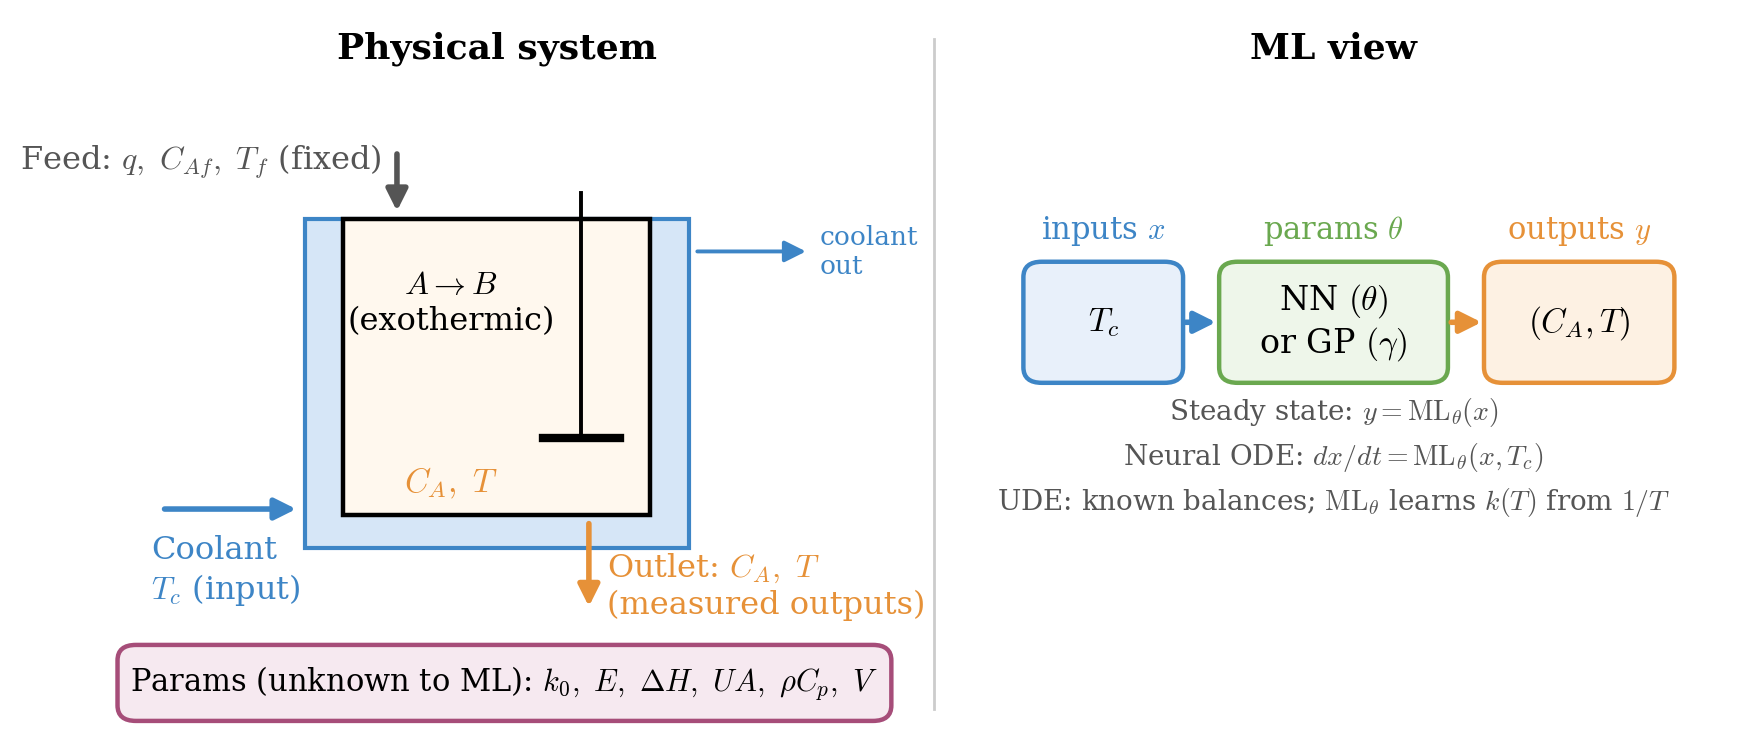

We use the same CSTR model as in the neural network tutorial. The states are the concentration $C_A$ (mol/L) and the
temperature $T$ (K); the input is the coolant temperature $T_c$ (K).

$$\frac{dC_A}{dt}=\frac{q}{V}(C_{Af}-C_A)-k_0e^{-E/RT}C_A$$

$$\frac{dT}{dt}=\frac{q}{V}(T_f-T)+\frac{(-\Delta H)}{\rho C_p}k_0e^{-E/RT}C_A+\frac{UA}{V\rho C_p}(T_c-T)$$

We run $N=15$ steady-state experiments with $T_c\in[285,302]$ K and Gaussian measurement noise with standard deviations
$\sigma=(0.005\ \mathrm{mol/L},\ 0.5\ \mathrm{K})$. Using the same random seed, we obtain **exactly the same data** as in the
neural network tutorial.

In [2]:
q, V = 100.0, 100.0          # L/min, L
CAf, Tf = 1.0, 350.0         # mol/L, K
rho, Cp = 1000.0, 0.239      # g/L, J/(g K)
dH = -5.0e4                  # J/mol
ER, k0 = 8750.0, 7.2e10      # K, 1/min
UA = 5.0e4                   # J/(min K)


def cstr_rhs(t, x, Tc):
    CA, T = x
    r = k0*np.exp(-ER/T)*CA
    dCA = q/V*(CAf - CA) - r
    dT = q/V*(Tf - T) - dH/(rho*Cp)*r + UA/(V*rho*Cp)*(Tc - T)
    return [dCA, dT]


def steady_state(Tc):
    # integrate long enough to reach steady state
    sol = solve_ivp(cstr_rhs, [0, 200.0], [0.9, 310.0], args=(Tc,),
                    method="LSODA", rtol=1e-8, atol=1e-10)
    return sol.y[:, -1]


labels = [r"$C_A$ (mol/L)", r"$T$ (K)"]
sigma = np.array([0.005, 0.5])

Tc_lo, Tc_hi = 285.0, 302.0
Tc_train = np.sort(rng.uniform(Tc_lo, Tc_hi, 15))
Tc_grid = np.linspace(280.0, 303.0, 93)

y_true = np.array([steady_state(Tc) for Tc in Tc_train])
y_obs = y_true + rng.normal(size=y_true.shape)*sigma
y_grid = np.array([steady_state(Tc) for Tc in Tc_grid])

### 2. Define the GP model

A GP treats the model as a random function. For each output $j$ (we build one GP per output), we postulate

$$y_\omega=m(x_\omega)+\epsilon_\omega,\qquad \mathbf{m}\sim\mathcal{N}(0,\mathbf{K}(\gamma)),\qquad \epsilon_\omega\sim\mathcal{N}(0,\sigma^2)$$

where $x=(T_c-293.5)/8.5$ is the scaled input. We use the radial basis function (RBF) kernel

$$k(x,x',\gamma)=\gamma_0\exp\left(-\frac{(x-x')^2}{2\gamma_1^2}\right)$$

with variance $\gamma_0$ and length scale $\gamma_1$. These are the only two parameters of the GP.

We also standardize the outputs (`normalize_y=True`), so the noise variance in standardized units is
$(\sigma_j/s_j)^2$, where $s_j$ is the standard deviation of the training outputs. We assume that the noise level is known.

### Training

The GP is trained by estimating $\gamma$ with maximum likelihood, using the marginal likelihood of the data:

$$\max_\gamma\;-\frac{1}{2}\log|\mathbf{C}(\gamma)|-\frac{1}{2}\mathbf{y}^T\mathbf{C}(\gamma)^{-1}\mathbf{y}-\frac{N}{2}\log 2\pi,
\qquad \mathbf{C}(\gamma)=\mathbf{K}(\gamma)+\sigma^2\mathbf{I}$$

Scikit-learn solves this problem with L-BFGS (a quasi-Newton method) from several starting points.

In [3]:
def scale_Tc(Tc):
    return (np.asarray(Tc) - 293.5)/8.5


x_train = scale_Tc(Tc_train)[:, None]
x_grid = scale_Tc(Tc_grid)[:, None]

gps = []
for j in range(2):
    kernel = ConstantKernel(1.0, (1e-3, 1e3))*RBF(1.0, (1e-2, 1e2))
    noise_var = (sigma[j]/y_obs[:, j].std())**2
    gp = GaussianProcessRegressor(kernel=kernel, alpha=noise_var,
                                  normalize_y=True, n_restarts_optimizer=10,
                                  random_state=SEED)
    gp.fit(x_train, y_obs[:, j])
    gps.append(gp)
    print(f"Output {j}: learned kernel {gp.kernel_}")
    print(f"          log marginal likelihood = {gp.log_marginal_likelihood_value_:.2f}")

Output 0: learned kernel 3.25**2 * RBF(length_scale=1.27)
          log marginal likelihood = -4.83
Output 1: learned kernel 4.31**2 * RBF(length_scale=3.3)
          log marginal likelihood = -3.55


### 3. Predict with the GP

The GP prediction at a new input $x$ is Gaussian, $\mathcal{N}(\mu(x),\sigma^2(x))$. We plot the mean prediction and
the 95% confidence interval $\mu(x)\pm1.96\,\sigma(x)$. The shaded region is the range covered by the training data.

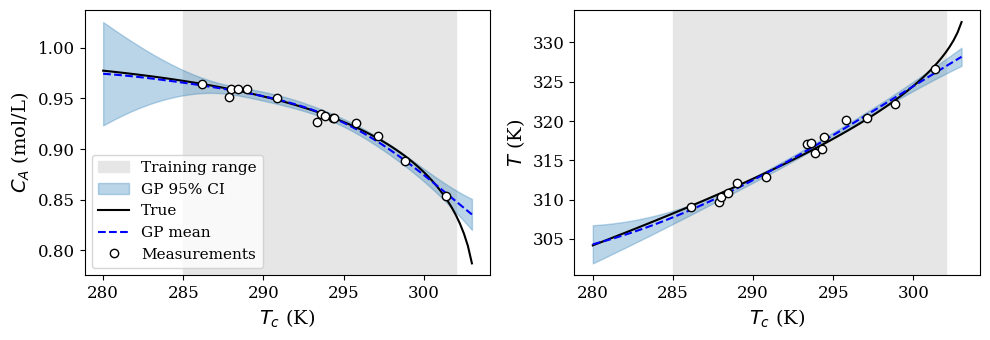

CA: RMSE inside range = 0.0030, outside range = 0.0139, mean std inside = 0.0028, outside = 0.0142
T: RMSE inside range = 0.4908, outside range = 1.3727, mean std inside = 0.2351, outside = 0.7654


In [4]:
mu = np.zeros((len(Tc_grid), 2))
sd = np.zeros((len(Tc_grid), 2))
for j, gp in enumerate(gps):
    mu[:, j], sd[:, j] = gp.predict(x_grid, return_std=True)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for j, ax in enumerate(axes):
    ax.axvspan(Tc_lo, Tc_hi, color="0.9", label="Training range")
    ax.fill_between(Tc_grid, mu[:, j] - 1.96*sd[:, j], mu[:, j] + 1.96*sd[:, j],
                    color="tab:blue", alpha=0.3, label="GP 95% CI")
    ax.plot(Tc_grid, y_grid[:, j], "k-", label="True")
    ax.plot(Tc_grid, mu[:, j], "b--", label="GP mean")
    ax.plot(Tc_train, y_obs[:, j], "o", mfc="w", mec="k", label="Measurements")
    ax.set(xlabel=r"$T_c$ (K)", ylabel=labels[j])
axes[0].legend(loc="lower left")
plt.tight_layout()
plt.show()

inside = (Tc_grid >= Tc_lo) & (Tc_grid <= Tc_hi)
for j, name in enumerate(["CA", "T"]):
    rmse_in = np.sqrt(np.mean((mu[inside, j] - y_grid[inside, j])**2))
    rmse_out = np.sqrt(np.mean((mu[~inside, j] - y_grid[~inside, j])**2))
    print(f"{name}: RMSE inside range = {rmse_in:.4f}, outside range = {rmse_out:.4f}, "
          f"mean std inside = {sd[inside, j].mean():.4f}, outside = {sd[~inside, j].mean():.4f}")

**Observations**

- Inside the training range, the GP mean captures the nonlinear steady-state map and the confidence interval is narrow.
- Outside the training range, the confidence interval widens: **the GP knows when it does not know**.
- For $T_c$ close to 303 K, the true temperature rises steeply (approach to ignition); the GP mean misses this,
  but the uncertainty band signals that predictions are unreliable there.
- This uncertainty information is what makes GPs so useful for experimental design and Bayesian optimization (Module 4).
- For comparison, the NN of the previous tutorial achieved similar accuracy inside the training range
  (RMSE of 0.005 mol/L and 0.45 K) but gave no warning outside of it.

### 4. Verify the GP formulas by hand

The GP is nonparametric: predictions are computed directly from the training data using

$$\mu(x)=\mathbf{k}(x)^T\mathbf{C}^{-1}\mathbf{y},\qquad
\sigma^2(x)=k(x,x)-\mathbf{k}(x)^T\mathbf{C}^{-1}\mathbf{k}(x)$$

where $\mathbf{k}_\omega(x)=k(x_\omega,x)$ and $\mathbf{C}=\mathbf{K}+\sigma^2\mathbf{I}$.
We compute these expressions for the temperature GP and compare them with scikit-learn.
Because we used `normalize_y=True`, the formulas are applied to the standardized outputs and the result is then rescaled.

In [5]:
j = 1
gp = gps[j]
y_mean, y_std = y_obs[:, j].mean(), y_obs[:, j].std()
y_s = (y_obs[:, j] - y_mean)/y_std              # standardized outputs

K = gp.kernel_(x_train)                         # K_{w,w'} = k(x_w, x_w')
C = K + gp.alpha*np.eye(len(x_train))           # C = K + sigma^2 I
k_star = gp.kernel_(x_train, x_grid)            # k(x_w, x) for all grid points
c_star = np.diag(gp.kernel_(x_grid))            # k(x, x)

mu_hand = k_star.T @ np.linalg.solve(C, y_s)
var_hand = c_star - np.sum(k_star*np.linalg.solve(C, k_star), axis=0)

mu_hand = mu_hand*y_std + y_mean                # back to physical units
sd_hand = np.sqrt(var_hand)*y_std

print("max |mean difference| =", np.max(np.abs(mu_hand - mu[:, j])))
print("max |std difference|  =", np.max(np.abs(sd_hand - sd[:, j])))

max |mean difference| = 2.2168933355715126e-12
max |std difference|  = 7.663036871718987e-13


The hand calculation reproduces the scikit-learn predictions (up to round-off).
Note that the prediction requires all training data: storing and factorizing $\mathbf{C}\in\mathbb{R}^{N\times N}$
scales as $\mathcal{O}(N^3)$, which limits GPs to small and medium datasets.

### 5. Key takeaways

- GPs are **flexible and powerful**: with only two hyperparameters per output, the GP captured the nonlinear steady-state
  behavior of the CSTR from 15 experiments.
- GPs are **nonparametric**: predictions are computed directly from the data, $\mu(x)=\mathbf{k}(x)^T\mathbf{C}^{-1}\mathbf{y}$,
  instead of from a trained parameter vector.
- GPs provide uncertainty for free; the uncertainty grows where there is no data. The price is $\mathcal{O}(N^3)$ scaling with the number of data points.

### 6. Optional exercises

1. **Amount of data.** Reduce the number of experiments to 5. How do the mean and the confidence interval change?
2. **Kernel.** Replace the RBF kernel by a Matérn kernel (`Matern(nu=1.5)`). How do the predictions change?
3. **Noise level.** Set the assumed noise to a much smaller value. What happens to the GP fit?
4. **Experimental design.** Which value of $T_c$ would you test next to learn the most about the reactor?
   (Hint: look for the largest $\sigma(x)$.) This idea is the basis of Bayesian optimization (Module 4).

### References

- Rasmussen, C. E., and Williams, C. K. I. (2006). *Gaussian Processes for Machine Learning*. MIT Press. https://gaussianprocess.org/gpml/
- Zavala, V. M. (2025). *Statistics for Chemical Engineers*. Cambridge University Press.